Matplotlib is building the font cache; this may take a moment.


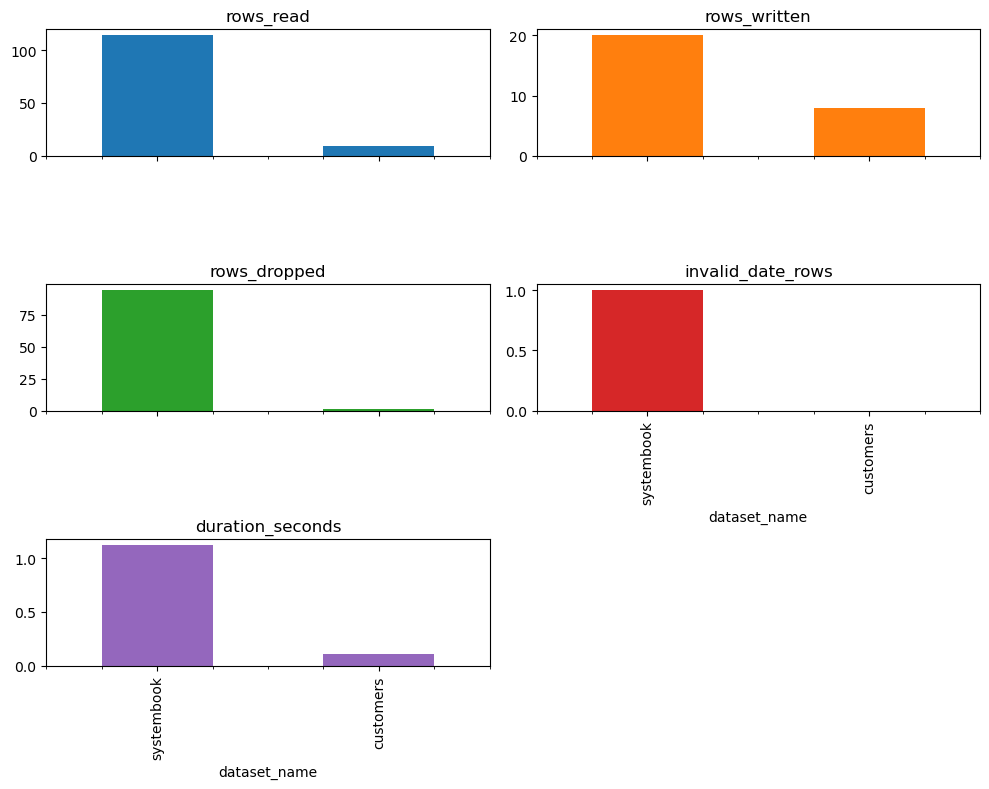

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

metrics = pd.read_csv("../data/pipeline_metrics.csv")
latest_run = metrics[metrics["run_id"] == metrics.iloc[-1]["run_id"]]

latest_run.set_index("dataset_name")[["rows_read", "rows_written", "rows_dropped", "invalid_date_rows", "duration_seconds"]
        ].plot(kind="bar", subplots=True, layout=(3, 2), figsize=(10, 8), legend=False)

plt.tight_layout()
plt.show()


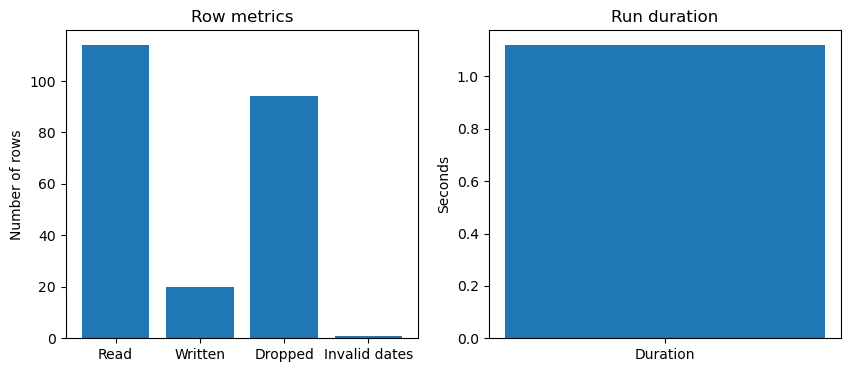

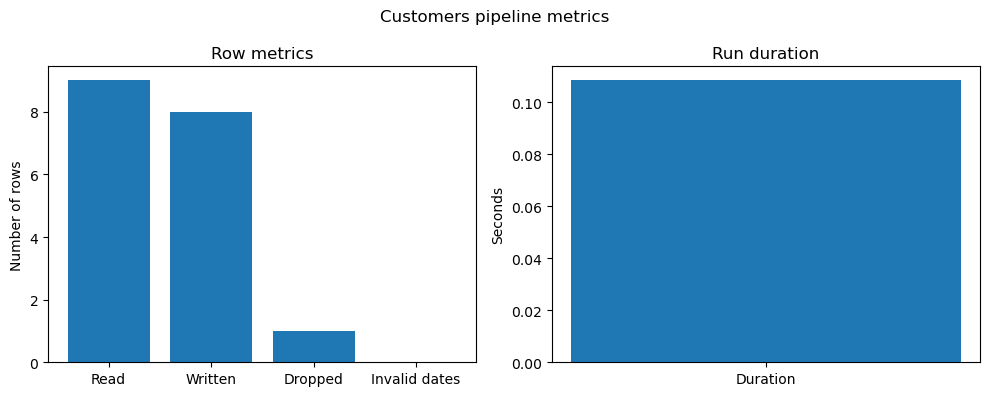

In [3]:


datasets = {
        "systembook": "Books",
        "customers": "Customers"}

for dataset_name, title in datasets.items():

    row = latest_run.loc[latest_run["dataset_name"] == dataset_name].iloc[0]

    fig, (ax_rows, ax_duration) = plt.subplots(1, 2, figsize=(10, 4) )

    row_metrics = ["rows_read", "rows_written", "rows_dropped", "invalid_date_rows"]
    row_values = [row[metric] for metric in row_metrics]

    ax_rows.bar(["Read", "Written", "Dropped", "Invalid dates"],row_values)
    ax_rows.set_title("Row metrics")
    ax_rows.set_ylabel("Number of rows")

    ax_duration.bar(["Duration"], [row["duration_seconds"]])
    ax_duration.set_title("Run duration")
    ax_duration.set_ylabel("Seconds")

fig.suptitle(f"{title} pipeline metrics")
plt.tight_layout()
plt.show()
